# Økonometri Aflevering
## Opsætning og biblioteker

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import scipy.stats as stats
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

## Hjælpefunktioner
Her defineres funktioner til beregning af OLS-estimater og F-tests, som benyttes på tværs af opgaverne.

In [2]:
def OLS_ren(X, y, navne, robust=False):
    n = X.shape[0]
    k = X.shape[1] - 1

    X_T_X_inv = np.linalg.inv(X.T @ X)
    betahat = X_T_X_inv @ X.T @ y
    
    y_hat = X @ betahat
    u_hat = y - y_hat
    y_bar = np.mean(y)

    SST = np.sum((y - y_bar)**2)
    SSR = np.sum(u_hat**2)
    SSE = np.sum((y_hat - y_bar)**2)
    R2 = SSE / SST
    
    if robust:
        S = X.T @ (X * (u_hat**2).reshape(-1, 1))
        var_betahatX = (n / (n - k - 1)) * (X_T_X_inv @ S @ X_T_X_inv)
        print("=== BEMÆRK: Bruger heteroskedasticitetsrobuste (HC1) standardfejl ===")
    else:
        resvar = (1 / (n - k - 1)) * np.dot(u_hat, u_hat)
        var_betahatX = resvar * X_T_X_inv

    se_betahat = np.sqrt(np.diagonal(var_betahatX))
    
    t_stat = betahat / se_betahat
    p_values = 2 * stats.t.sf(np.abs(t_stat), n - k - 1)

    print("==============================================================================")
    print(f"Number of Observations: {n}")
    print(f"Residual Degrees of Freedom: {n - k - 1}")
    print(f"R-squared: {R2:.4f}")
    print(f"TSS: {SST:.4f}, ESS: {SSE:.4f}, RSS: {SSR:.4f}")
    print("==============================================================================")
    
    results = pd.DataFrame({
        'Koefficient': betahat,
        'Std.fejl': se_betahat,
        't-værdi': t_stat,
        'P>|t|': p_values
    }, index=navne)
    
    formatted_results = results.copy()
    for col in formatted_results.columns:
        formatted_results[col] = formatted_results[col].apply(lambda x: f"{x:.4f}")
    
    display(formatted_results)

## Opgave 1.A

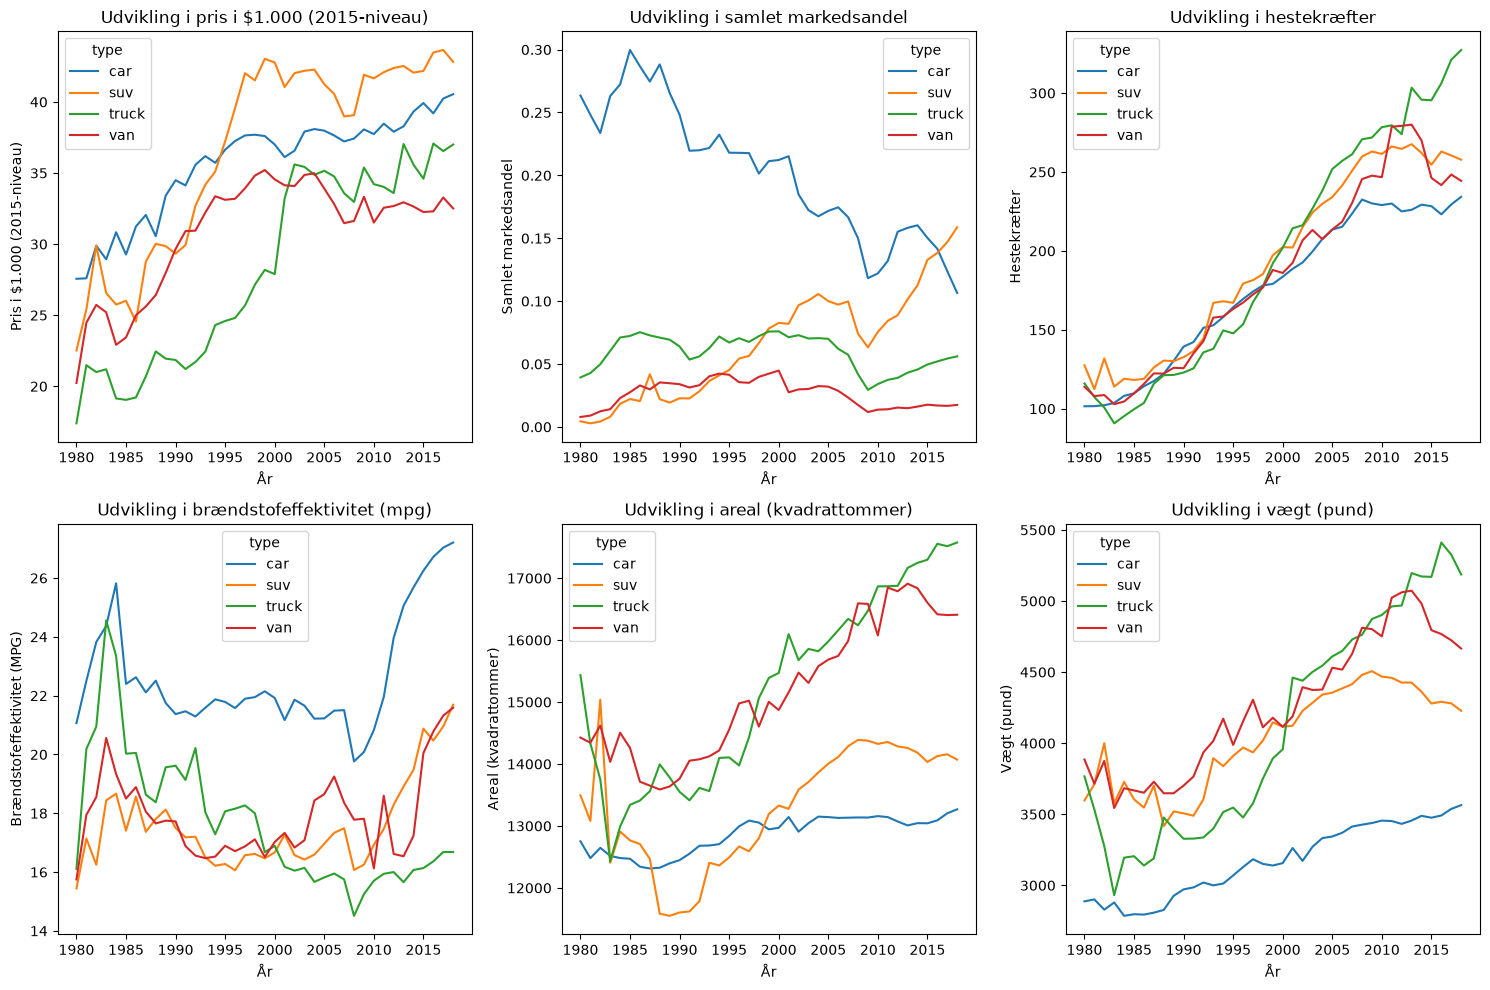

In [3]:
df = pd.read_csv("data/cars.csv") 
pd.options.display.float_format = "{:.4f}".format

biltyper = ['car', 'suv', 'truck', 'van']
df['type'] = df[biltyper].idxmax(axis=1)

variable_til_plot = ['price', 'market_share', 'hp', 'mpg', 'footprint', 'weight']

df_agg = df.groupby(['year', 'type']).agg({
    'price': 'mean',
    'market_share': 'sum', 
    'hp': 'mean',
    'mpg': 'mean',
    'footprint': 'mean',
    'weight': 'mean'
})

pæne_titler = {
    'price': 'Pris i $1.000 (2015-niveau)',
    'market_share': 'Samlet markedsandel', 
    'hp': 'Hestekræfter',
    'mpg': 'Brændstofeffektivitet (MPG)',
    'footprint': 'Areal (kvadrattommer)',
    'weight': 'Vægt (pund)'
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, var in zip(axes.flatten(), variable_til_plot):
    df_agg[var].unstack().plot(ax=ax)
    
    ax.set_title(f'Udvikling i {pæne_titler[var].lower()}')
    ax.set_ylabel(pæne_titler[var])
    ax.set_xlabel('År')

plt.tight_layout()
plt.show()

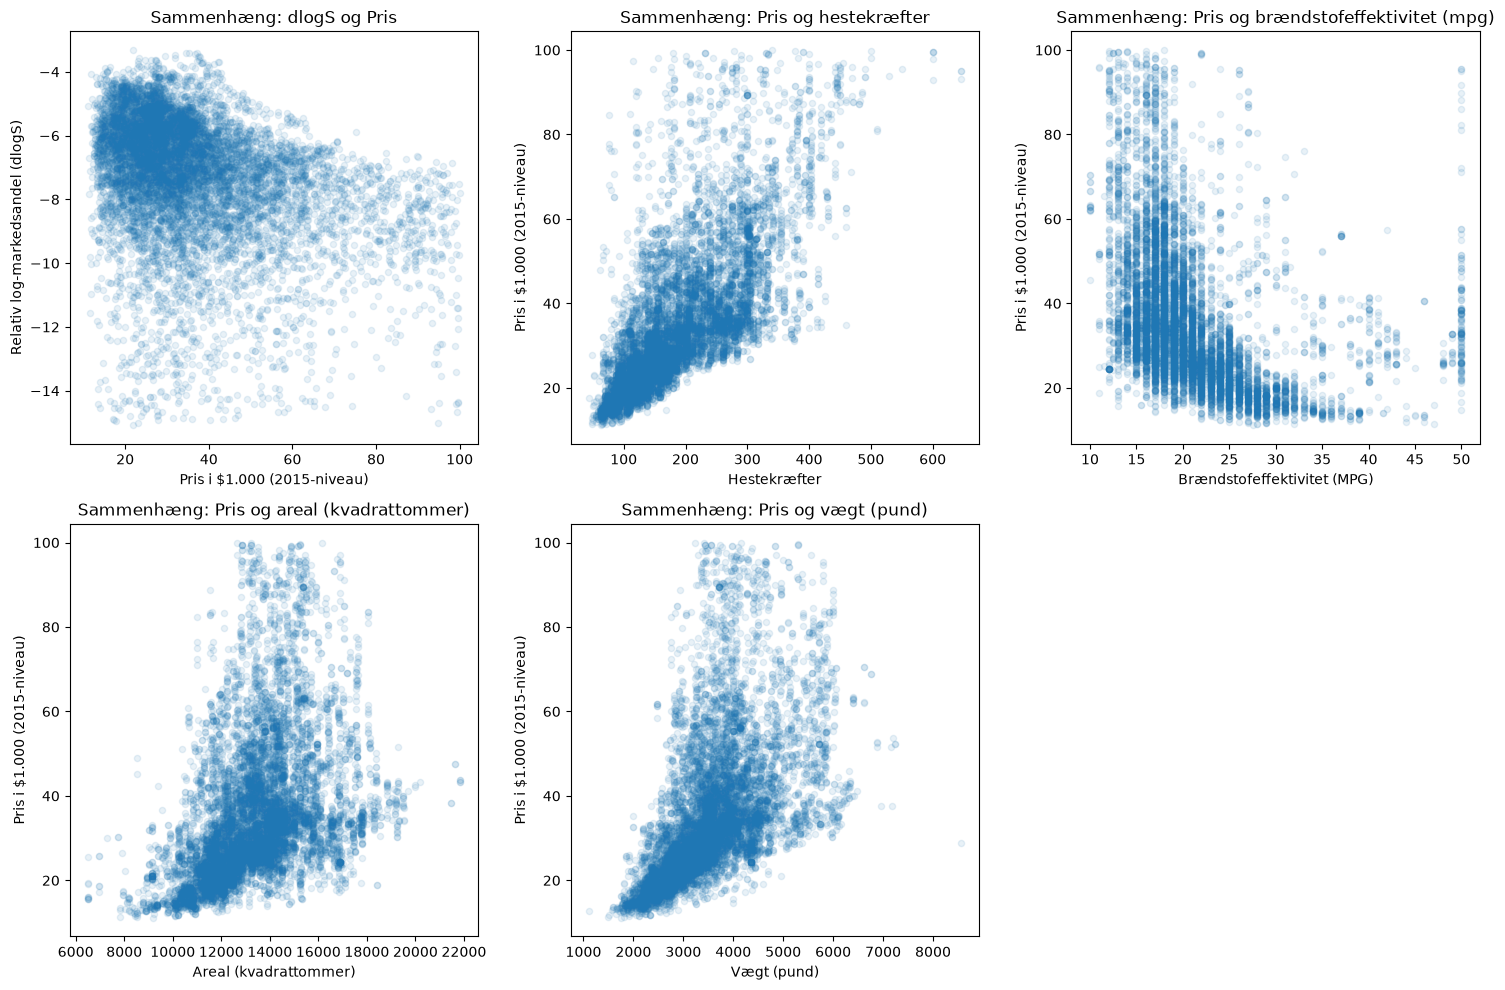

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes_flat = axes.flatten()

df.plot.scatter(x='price', y='dlogS', alpha=0.1, ax=axes_flat[0])
axes_flat[0].set_title('Sammenhæng: dlogS og Pris')
axes_flat[0].set_xlabel('Pris i $1.000 (2015-niveau)')
axes_flat[0].set_ylabel('Relativ log-markedsandel (dlogS)')

fysiske_vars = ['hp', 'mpg', 'footprint', 'weight']
pæne_titler = {
    'hp': 'Hestekræfter',
    'mpg': 'Brændstofeffektivitet (MPG)',
    'footprint': 'Areal (kvadrattommer)',
    'weight': 'Vægt (pund)'
}

for i, var in enumerate(fysiske_vars):
    ax = axes_flat[i+1]
    df.plot.scatter(x=var, y='price', alpha=0.1, ax=ax)
    ax.set_title(f'Sammenhæng: Pris og {pæne_titler[var].lower()}')
    ax.set_xlabel(pæne_titler[var])
    ax.set_ylabel('Pris i $1.000 (2015-niveau)')

fig.delaxes(axes_flat[5])

plt.tight_layout()
plt.show()

## Opgave 1.B)

In [5]:
df = pd.read_csv("data/cars.csv")
y = df['dlogS'].values

df['konstant'] = 1
kontrol_variable = ['hp', 'mpg', 'height', 'footprint', 'weight', 'number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']
year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=int)
years = list(year_dummies.columns)
df = pd.concat([df, year_dummies], axis=1)

kontinuerte_vars = ['hp', 'mpg', 'height', 'footprint', 'weight', 'number_trims']
log_vars_names = [f'log_{var}' for var in kontinuerte_vars]
for var, log_var in zip(kontinuerte_vars, log_vars_names):
    df[log_var] = np.log(df[var])

andre_kontrol = ['releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']
kontrol_vars_log_spec = log_vars_names + andre_kontrol

navne_1 = ['konstant', 'price']
X1 = df[navne_1].values

navne_2 = ['konstant', 'price'] + kontrol_variable
X2 = df[navne_2].values

navne_3 = ['konstant', 'price'] + kontrol_variable + years
X3 = df[navne_3].values

navne_4 = ['konstant', 'price'] + kontrol_vars_log_spec + years
X4 = df[navne_4].values

print("=== SPECIFIKATION 1 ===")
OLS_ren(X1, y, navne_1)

print("\n=== SPECIFIKATION 2 ===")
OLS_ren(X2, y, navne_2)

print("\n=== SPECIFIKATION 3 ===")
OLS_ren(X3, y, navne_3)

print("\n=== SPECIFIKATION 4 ===")
OLS_ren(X4, y, navne_4)


=== SPECIFIKATION 1 ===
Number of Observations: 9694
Residual Degrees of Freedom: 9692
R-squared: 0.1062
TSS: 37300.6952, ESS: 3961.2203, RSS: 33339.4749


,Koefficient,Std.fejl,t-værdi,P>|t|
konstant,-5.9072,0.0439,-134.5673,0.0000
price,-0.0373,0.0011,-33.9345,0.0000



=== SPECIFIKATION 2 ===
Number of Observations: 9694
Residual Degrees of Freedom: 9679
R-squared: 0.3001
TSS: 37300.6952, ESS: 11192.3322, RSS: 26108.3630


,Koefficient,Std.fejl,t-værdi,P>|t|
konstant,-5.4138,0.2908,-18.6167,0.0000
price,-0.0243,0.0016,-15.0567,0.0000
hp,-0.0038,0.0004,-10.1846,0.0000
mpg,-0.0427,0.0037,-11.6670,0.0000
height,-0.0237,0.0048,-4.9020,0.0000
footprint,0.0004,0.0000,19.1176,0.0000
weight,-0.0007,0.0001,-10.9435,0.0000
number_trims,0.0552,0.0019,29.1944,0.0000
releaseYear,-1.0643,0.0614,-17.3242,0.0000
yearsSinceDesign,-0.1269,0.0059,-21.5151,0.0000



=== SPECIFIKATION 3 ===
Number of Observations: 9694
Residual Degrees of Freedom: 9641
R-squared: 0.3410
TSS: 37300.6952, ESS: 12720.2260, RSS: 24580.4692


,Koefficient,Std.fejl,t-værdi,P>|t|
konstant,-6.8066,0.3177,-21.4231,0.0000
price,-0.0370,0.0017,-21.9032,0.0000
hp,0.0024,0.0005,4.8783,0.0000
mpg,-0.0115,0.0042,-2.7218,0.0065
height,-0.0154,0.0047,-3.2439,0.0012
footprint,0.0003,0.0000,16.6201,0.0000
weight,-0.0006,0.0001,-9.0157,0.0000
number_trims,0.0530,0.0018,28.6390,0.0000
releaseYear,-1.2272,0.0608,-20.1777,0.0000
yearsSinceDesign,-0.1278,0.0058,-22.0623,0.0000



=== SPECIFIKATION 4 ===
Number of Observations: 9694
Residual Degrees of Freedom: 9641
R-squared: 0.5065
TSS: 37300.6952, ESS: 18893.6537, RSS: 18407.0415


,Koefficient,Std.fejl,t-værdi,P>|t|
konstant,-25.4344,1.6540,-15.3772,0.0000
price,-0.0298,0.0014,-20.9693,0.0000
log_hp,0.4285,0.0994,4.3118,0.0000
log_mpg,0.3280,0.1079,3.0395,0.0024
log_height,-1.2168,0.2632,-4.6236,0.0000
log_footprint,2.9136,0.2203,13.2249,0.0000
log_weight,-0.8093,0.2115,-3.8262,0.0001
log_number_trims,1.1869,0.0181,65.4406,0.0000
releaseYear,-0.5031,0.0542,-9.2826,0.0000
yearsSinceDesign,-0.1077,0.0050,-21.3537,0.0000


## Opgave 1.C

In [6]:
OLS_ren(X4, y, navne_4, robust=True)

=== BEMÆRK: Bruger heteroskedasticitetsrobuste (HC1) standardfejl ===
Number of Observations: 9694
Residual Degrees of Freedom: 9641
R-squared: 0.5065
TSS: 37300.6952, ESS: 18893.6537, RSS: 18407.0415


,Koefficient,Std.fejl,t-værdi,P>|t|
konstant,-25.4344,1.7798,-14.2903,0.0000
price,-0.0298,0.0014,-21.2818,0.0000
log_hp,0.4285,0.1049,4.0834,0.0000
log_mpg,0.3280,0.1218,2.6925,0.0071
log_height,-1.2168,0.2824,-4.3080,0.0000
log_footprint,2.9136,0.2287,12.7385,0.0000
log_weight,-0.8093,0.2175,-3.7215,0.0002
log_number_trims,1.1869,0.0214,55.4625,0.0000
releaseYear,-0.5031,0.0536,-9.3805,0.0000
yearsSinceDesign,-0.1077,0.0061,-17.7074,0.0000


## Opgave 2.A

In [7]:
make_dummies = pd.get_dummies(df['make'], drop_first=True, dtype=int)
makes = list(make_dummies.columns)
df = pd.concat([df, make_dummies], axis=1)

navne_dummy = navne_4 + makes
X_dummy = df[navne_dummy].values 

model_dummy = sm.OLS(y, X_dummy).fit(cov_type='HC1')
print("--- Dummy-model (LSDV) ---")
print(model_dummy.summary(xname=navne_dummy))

df_within = df.copy()
variabler_til_transform = ['dlogS', 'price'] + kontrol_vars_log_spec + years

for var in variabler_til_transform:
    make_mean = df_within.groupby('make')[var].transform('mean')
    df_within[var] = df_within[var] - make_mean

navne_within = ['price'] + kontrol_vars_log_spec + years
X_within = df_within[navne_within].values
y_within = df_within['dlogS'].values

model_within = sm.OLS(y_within, X_within).fit(cov_type='HC1')
print(model_within.summary(xname=navne_within))

--- Dummy-model (LSDV) ---
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.589
Model:                            OLS   Adj. R-squared:                  0.584
Method:                 Least Squares   F-statistic:                     148.4
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:21:10   Log-Likelihood:                -15978.
No. Observations:                9694   AIC:                         3.218e+04
Df Residuals:                    9580   BIC:                         3.300e+04
Df Model:                         113                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
konstant     

e:\Kode\økonometri\EconometricsA\.venv\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 113, but rank is 109
  res = self.wald_test(


### Udregning af TSS, ESS og RSS til 2.A

In [8]:
print("--- Dummy-model (LSDV) ---")
print(f"TSS: {model_dummy.centered_tss:.2f}")
print(f"ESS: {model_dummy.ess:.2f}")
print(f"RSS: {model_dummy.ssr:.2f}")

print("\n--- Within-transformation ---")
print(f"TSS: {model_within.centered_tss:.2f}")
print(f"ESS: {model_within.ess:.2f}")
print(f"RSS: {model_within.ssr:.2f}")

--- Dummy-model (LSDV) ---
TSS: 37300.70
ESS: 21967.19
RSS: 15333.51

--- Within-transformation ---
TSS: 30415.61
ESS: 15082.11
RSS: 15333.51


## Opgave 2.C

In [9]:
make_dummies = pd.get_dummies(df['make'], prefix='m', drop_first=True, dtype=int)
makes = list(make_dummies.columns)

if 'm_audi' not in df.columns: 
    df = pd.concat([df, make_dummies], axis=1)

eksogene_navne = ['konstant'] + kontrol_vars_log_spec + years + makes

y = df['dlogS']
X_eksogen = df[eksogene_navne]
X_endogen = df[['price']]
Z_instrument = df[['RXR']]

# ==========================================
# TRIN 1: FIRST STAGE REGRESSION (Ligning 6)
# ==========================================
navne_first = ['RXR'] + eksogene_navne
Z_first_stage = df[navne_first].values

print("=== FIRST STAGE: Test af instrumentet RXR ===")
OLS_ren(Z_first_stage, df['price'].values, navne_first, robust=True)

# ==========================================
# TRIN 2: 2SLS ESTIMATION (Ligning 4)
# ==========================================
print("\n=== 2SLS RESULTATER ===")
iv_model = IV2SLS(dependent=y, exog=X_eksogen, endog=X_endogen, instruments=Z_instrument).fit(cov_type='robust')
print(iv_model.summary)

=== FIRST STAGE: Test af instrumentet RXR ===
=== BEMÆRK: Bruger heteroskedasticitetsrobuste (HC1) standardfejl ===
Number of Observations: 9694
Residual Degrees of Freedom: 9580
R-squared: 0.8147
TSS: 2843143.1020, ESS: 2316213.9548, RSS: 526929.1472


,Koefficient,Std.fejl,t-værdi,P>|t|
RXR,4.1465,0.4504,9.2056,0.0000
konstant,-196.1827,12.5709,-15.6061,0.0000
log_hp,16.6868,0.7989,20.8882,0.0000
log_mpg,5.0653,0.7735,6.5484,0.0000
log_height,-16.0567,1.7221,-9.3238,0.0000
...,...,...,...,...
m_toyota,-1.6504,0.5597,-2.9488,0.0032
m_triumph,9.8694,0.9873,9.9963,0.0000
m_volkswagen,0.5887,0.6407,0.9189,0.3582
m_volvo,3.5802,0.6231,5.7459,0.0000



=== 2SLS RESULTATER ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:                  dlogS   R-squared:                      0.3269
Estimator:                    IV-2SLS   Adj. R-squared:                 0.3190
No. Observations:                9694   F-statistic:                 4.412e+15
Date:                Wed, Oct 28 2026   P-value (F-stat)                0.0000
Time:                        22:21:10   Distribution:                chi2(113)
Cov. Estimator:                robust                                         
                                                                              
                                Parameter Estimates                                 
                  Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------------
konstant            -40.856     5.4541    -7.4910     0.0000     -51.546     -30.166
log

## Opgave 3.A

In [10]:
make_dummies = pd.get_dummies(df['make'], prefix='m', drop_first=True, dtype=int)
makes = list(make_dummies.columns)


if 'm_audi' not in df.columns:
    df = pd.concat([df, make_dummies], axis=1)


gh_instrumenter = ['gh_log_height', 'gh_log_footprint', 'gh_log_hp', 'gh_log_mpg', 'gh_log_weight']
Z_instrument_GH = df[gh_instrumenter]

print("\n=== 2SLS RESULTATER (Kun GH) ===")
iv_model_GH = IV2SLS(dependent=y, exog=X_eksogen, endog=X_endogen, instruments=Z_instrument_GH).fit(cov_type='robust')
print(iv_model_GH.summary)

# 1. Test for instrumenternes relevans i First Stage
print("=== FIRST STAGE DIAGNOSTICS ===")
print(iv_model_GH.first_stage)

# 2. Overidentifikationstest for instrumenternes eksogenitet
print("\n=== OVERIDENTIFIKATIONSTEST ===")
print(iv_model_GH.wooldridge_overid)

ghRXR_instrumenter = ['gh_log_height', 'gh_log_footprint', 'gh_log_hp', 'gh_log_mpg', 'gh_log_weight', 'RXR']
Z_instrument_GHRXR = df[ghRXR_instrumenter]

print("\n=== 2SLS RESULTATER (Kun GH) ===")
iv_model_GHRXR = IV2SLS(dependent=y, exog=X_eksogen, endog=X_endogen, instruments=Z_instrument_GHRXR).fit(cov_type='robust')
print(iv_model_GHRXR.summary)

# 1. Test for instrumenternes relevans i First Stage
print("=== FIRST STAGE DIAGNOSTICS ===")
print(iv_model_GHRXR.first_stage)

# 2. Overidentifikationstest for instrumenternes eksogenitet
print("\n=== OVERIDENTIFIKATIONSTEST ===")
print(iv_model_GHRXR.wooldridge_overid)


=== 2SLS RESULTATER (Kun GH) ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:                  dlogS   R-squared:                      0.5858
Estimator:                    IV-2SLS   Adj. R-squared:                 0.5810
No. Observations:                9694   F-statistic:                -2.078e+17
Date:                Wed, Oct 28 2026   P-value (F-stat)                1.0000
Time:                        22:21:11   Distribution:                chi2(113)
Cov. Estimator:                robust                                         
                                                                              
                                Parameter Estimates                                 
                  Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------------
konstant            -12.320     2.0176    -6.1063     0.0000     -16.275     -8

## Opgave 3.B

       elasticity_ols  elasticity_iv    mc_ols     mc_iv  markup_ols  \
count       9694.0000      9694.0000 9694.0000 9694.0000   9694.0000   
mean          -1.2134        -6.0994    6.3317   30.1361      0.9980   
std            0.5774         2.9023   17.1433   17.1299      0.4242   
min           -3.3687       -16.9332  -18.6568    5.2161      0.2969   
25%           -1.4611        -7.3446   -5.6255   18.1712      0.6844   
50%           -1.0713        -5.3852    2.1171   25.9077      0.9334   
75%           -0.8106        -4.0746   13.6867   37.4951      1.2337   
max           -0.3740        -1.8798   70.3050   94.0816      2.6740   

       markup_iv  
count  9694.0000  
mean      0.1985  
std       0.0844  
min       0.0591  
25%       0.1362  
50%       0.1857  
75%       0.2454  
max       0.5320  


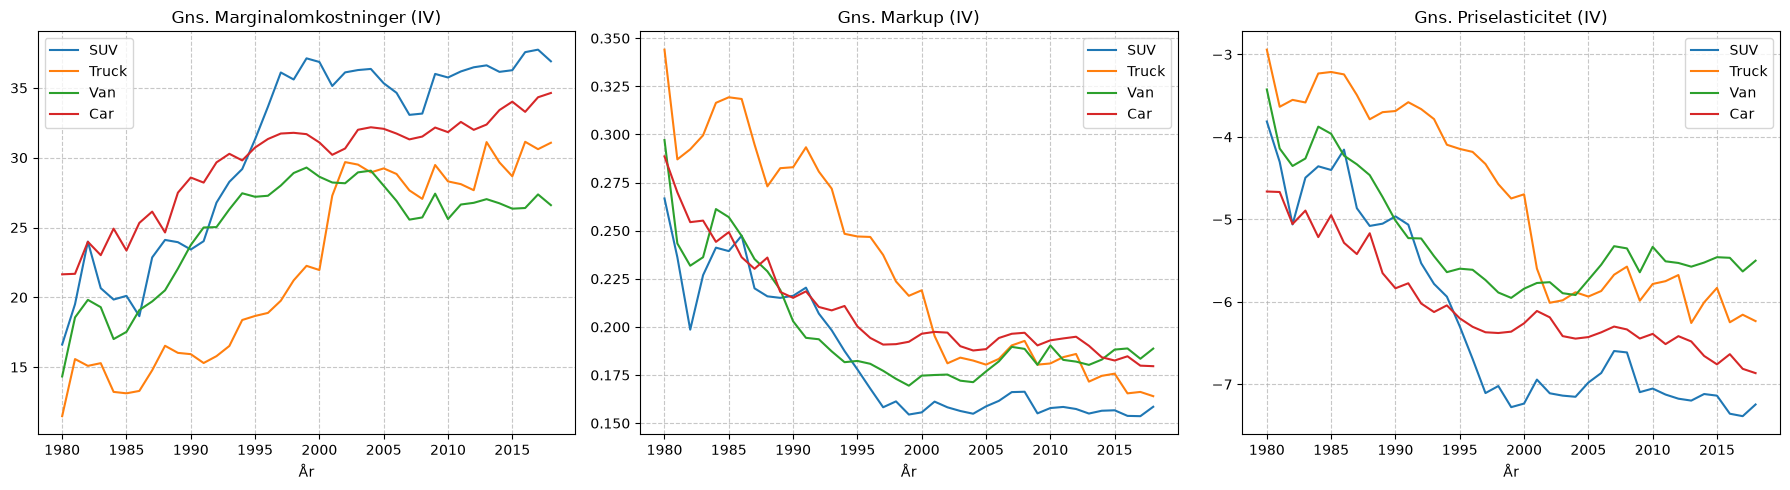

In [11]:
alpha_ols = -0.0337
alpha_iv = -0.1694
df['elasticity_ols'] = alpha_ols * df['price'] * (1 - df['market_share'])

# Marginalomkostninger (MC): p - 1 / (-alpha * (1 - s))
df['mc_ols'] = df['price'] - (1 / (-alpha_ols * (1 - df['market_share'])))

# Markup: (p - mc) / p
df['markup_ols'] = (df['price'] - df['mc_ols']) / df['price']

# --- IV BEREGNINGER ---
df['elasticity_iv'] = alpha_iv * df['price'] * (1 - df['market_share'])
df['mc_iv'] = df['price'] - (1 / (-alpha_iv * (1 - df['market_share'])))
df['markup_iv'] = (df['price'] - df['mc_iv']) / df['price']

variabler_til_tjek = [
    'elasticity_ols', 'elasticity_iv', 
    'mc_ols', 'mc_iv', 
    'markup_ols', 'markup_iv'
]

print(df[variabler_til_tjek].describe())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

variabler = ['mc_iv', 'markup_iv', 'elasticity_iv']
titler = ['Gns. Marginalomkostninger (IV)', 'Gns. Markup (IV)', 'Gns. Priselasticitet (IV)']

tidsvariabel = 'year' 

for i, var in enumerate(variabler):

    axes[i].plot(df[df['suv'] == 1].groupby(tidsvariabel)[var].mean(), label='SUV')
    axes[i].plot(df[df['truck'] == 1].groupby(tidsvariabel)[var].mean(), label='Truck')
    axes[i].plot(df[df['van'] == 1].groupby(tidsvariabel)[var].mean(), label='Van')
    axes[i].plot(df[df['car'] == 1].groupby(tidsvariabel)[var].mean(), label='Car')

   
    axes[i].set_title(titler[i])
    axes[i].set_xlabel('År')
    axes[i].grid(True, linestyle='--', alpha=0.7)
    axes[i].legend()


plt.tight_layout()
plt.show()

## Opgave 3.C

In [12]:
pd.set_option('display.max_rows', None)
y_3c = np.log(df['mc_iv']).values

make_dummies = pd.get_dummies(df['make'], prefix='make', drop_first=True, dtype=int)
makes = list(make_dummies.columns)

df = df.loc[:, ~df.columns.duplicated()] 
df = pd.concat([df, make_dummies], axis=1)

navne_3c = ['konstant'] + kontrol_vars_log_spec + ['RXR'] + makes + years
X_3c = df[navne_3c].values

print("=== OPGAVE 3C: Hedonisk marginalomkostningsfunktion ===")
OLS_ren(X_3c, y_3c, navne_3c, robust=True)

=== OPGAVE 3C: Hedonisk marginalomkostningsfunktion ===
=== BEMÆRK: Bruger heteroskedasticitetsrobuste (HC1) standardfejl ===
Number of Observations: 9694
Residual Degrees of Freedom: 9580
R-squared: 0.8793
TSS: 2874.6517, ESS: 2527.6698, RSS: 346.9819


,Koefficient,Std.fejl,t-værdi,P>|t|
konstant,-6.1841,0.3463,-17.8584,0.0000
log_hp,0.4663,0.0196,23.7854,0.0000
log_mpg,0.1115,0.0221,5.0525,0.0000
log_height,-0.7765,0.0517,-15.0163,0.0000
log_footprint,-0.1368,0.0442,-3.0958,0.0020
log_weight,1.3618,0.0467,29.1650,0.0000
log_number_trims,-0.0306,0.0026,-11.8003,0.0000
releaseYear,-0.0126,0.0086,-1.4719,0.1411
yearsSinceDesign,-0.0011,0.0008,-1.3851,0.1661
sport,0.1563,0.0087,17.9527,0.0000


## Opgave 4.C

In [13]:
n = 500
def simuler(n, gamma1=1, gamma2=1):


    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25


    z_i = np.random.normal(loc = 0 , scale= 1, size = n)
    xi_i = np.random.normal(loc = 0,  scale= 1, size = n)
    nu_i = np.random.normal(loc = 0, scale= 1, size = n)
    eta_0 = (gamma0-beta0) / (beta1- gamma1)
    eta_1 = gamma2 / (beta1-gamma1)
    u_i = (nu_i - xi_i) / (beta1-gamma1)
    p_i = eta_0 + eta_1 * z_i + u_i
    y = beta0 + beta1*p_i + xi_i

    X_ols = sm.add_constant(p_i)
    ols_res = sm.OLS(y, X_ols).fit()
    beta1_OLS = np.array(ols_res.params)[1]

    const = np.ones(n)
    iv_res = IV2SLS(dependent=y, exog=const, endog=p_i, instruments=z_i).fit()
    beta1_IV = np.array(iv_res.params)[1]

    return beta1_OLS, beta1_IV

def monte_carlo (reps=500, gamma1=1, gamma2=1):
    np.random.seed(0)

    beta1_ols_results = []
    beta1_iv_results = []

    for rep in range(reps):
        b_ols, b_iv = simuler(n, gamma1=gamma1, gamma2=gamma2)
        beta1_ols_results.append(b_ols)
        beta1_iv_results.append(b_iv)
        
    true_beta1 = -0.1
    bias_ols = np.mean(beta1_ols_results) - true_beta1
    bias_iv = np.mean(beta1_iv_results) - true_beta1
    
    var_ols = np.var(beta1_ols_results, ddof=1)
    var_iv = np.var(beta1_iv_results, ddof=1)
    
    return bias_ols, var_ols, bias_iv, var_iv

print("Scenarie 1 (Baseline):")
bias_ols1, var_ols1, bias_iv1, var_iv1 = monte_carlo(reps=500, gamma1=1, gamma2=1)
print(f"OLS - Bias: {bias_ols1:.5f} | Varians: {var_ols1:.5f}")
print(f"IV  - Bias: {bias_iv1:.5f} | Varians: {var_iv1:.5f}\n")

print("Scenarie 2 (gamma2 = 0.25):")
bias_ols2, var_ols2, bias_iv2, var_iv2 = monte_carlo(reps=500, gamma1=1, gamma2=0.25)
print(f"OLS - Bias: {bias_ols2:.5f} | Varians: {var_ols2:.5f}")
print(f"IV  - Bias: {bias_iv2:.5f} | Varians: {var_iv2:.5f}\n")

print("Scenarie 3 (gamma1 = 0.25):")
bias_ols3, var_ols3, bias_iv3, var_iv3 = monte_carlo(reps=500, gamma1=0.25, gamma2=1)
print(f"OLS - Bias: {bias_ols3:.5f} | Varians: {var_ols3:.5f}")
print(f"IV  - Bias: {bias_iv3:.5f} | Varians: {var_iv3:.5f}")

Scenarie 1 (Baseline):
OLS - Bias: 0.36753 | Varians: 0.00056
IV  - Bias: -0.00030 | Varians: 0.00236

Scenarie 2 (gamma2 = 0.25):
OLS - Bias: 0.53391 | Varians: 0.00064
IV  - Bias: -0.03065 | Varians: 0.05343

Scenarie 3 (gamma1 = 0.25):
OLS - Bias: 0.11694 | Varians: 0.00006
IV  - Bias: -0.00010 | Varians: 0.00024
